# El balance poblacional de Whiten paso a paso: la matriz de quiebre, la masa circulante y el producto

**Pregunta:** ¿Cuántas veces pasa por el apriete una unidad de alimentación con la abertura de S01, qué producto entrega el balance, y cómo crece la recirculación al cerrar la abertura?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema y el tema 02
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook usted puede:

- construir la matriz de quiebre B en la malla de tamices y comprobar que es estrictamente triangular inferior con columnas que conservan la masa;
- escribir el balance de la cámara, ver por qué necesita una solución lineal, y resolverlo;
- leer la solución como la masa que llega a la zona de quiebre, y de ella el número de eventos de apriete por unidad de alimentación;
- derivar el producto de la solución y confirmar que el solucionador propio del motor devuelve los mismos números;
- seguir la recirculación al cerrar la abertura de lado cerrado.

## Preparación

Numpy y matplotlib; el álgebra lineal del notebook es la del propio motor.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones son `assemble_chamber`, que arma el vector de clasificación y la matriz de quiebre de un punto de operación exactamente como lo hace el motor, el solucionador LU y el indicador de condicionamiento del motor, el propio solucionador de Whiten, y las utilidades de tamices y el oráculo.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher import Operating, evaluate, grid_edges, grid_mid
from pipeline.model.crusher.linalg import solve_lu, cond_proxy
from pipeline.model.crusher.whiten import assemble_chamber, whiten_solve
from pipeline.model.crusher.sieve import to_psd, size_at_passing
from pipeline.oracles import mass_closure
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

El caso de referencia S01 otra vez. Propietario: este repositorio, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Clase de licencia: MIT; los artefactos versionados los escribe el pipeline a partir de los parámetros de cada caso. Archivo leído: `data/derived/manifests/S01.json`, bloque `params`.

La celda lee el punto de operación y ejecuta el motor una vez para obtener la distribución de alimentación en la malla.

In [2]:
# Lea S01, ejecute el motor una vez para su alimentación en la malla y fije las constantes de la malla
manifest = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))
op = Operating(**manifest["params"])
result = evaluate(op)
edges, mids = grid_edges(), grid_mid()
K = len(mids)
feed = np.array(result.feed.mass)
print("clases:", K, "| masa de alimentación:", feed.sum().round(12), "| F80", round(result.f80, 2), "mm")

clases: 28 | masa de alimentación: 1.0 | F80 126.03 mm


## Método

**Paso 1, las dos matrices.** El balance necesita la selección y el quiebre en la misma malla. La selección es la clasificación evaluada en el tamaño medio de cada clase, un vector $c$. El quiebre es la matriz $B$ cuyo elemento $B_{ij}$ es la fracción de masa del material quebrado de la clase $j$ que va a la clase más fina $i$; se construye con la función de aparición del notebook 01, integrada sobre los bordes de clase, con cada columna renormalizada para que la masa quebrada se conserve. Como los fragmentos son siempre más finos que su madre, solo las clases bajo $j$ reciben masa: $B$ es estrictamente triangular inferior. La celda pide ambas a `assemble_chamber`. Esa función hace la construcción del notebook 01 en la malla del motor, la energía específica, t10 y el peso de aparición para $B$ y las constantes K1, K2, K3 de la abertura para $c$, y entrega el par $(c, B)$ que el propio `evaluate` resuelve. Luego la celda comprueba las tres propiedades de $B$.

In [3]:
# Pida al pipeline c y B de S01 y compruebe la estructura de B
c, B = assemble_chamber(op)
column_error = np.abs(B.sum(axis=0)[:-1] - 1).max()
n_one, n_mid, n_zero = int((c == 1).sum()), int(((c > 0) & (c < 1)).sum()), int((c == 0).sum())
print("formas de c y B:", c.shape, B.shape)
print("elementos sobre o en la diagonal:", np.count_nonzero(np.triu(B)))
print("mayor error de suma de columna (todas menos la última):", column_error)
print("clases con C = 1, entre 0 y 1, y 0:", n_one, n_mid, n_zero)

formas de c y B: (28,) (28, 28)
elementos sobre o en la diagonal: 0
mayor error de suma de columna (todas menos la última): 4.440892098500626e-16
clases con C = 1, entre 0 y 1, y 0: 4 2 22


La figura muestra $B$ como imagen en una escala de color logarítmica: un triángulo inferior cuya banda brillante queda justo bajo la diagonal en las clases gruesas, porque una partícula se quiebra sobre todo en fragmentos pocas clases más finos, y se desvanece hacia abajo a la izquierda, donde las razones de tamaño grandes son raras. El panel derecho muestra $c$ contra el índice de clase.

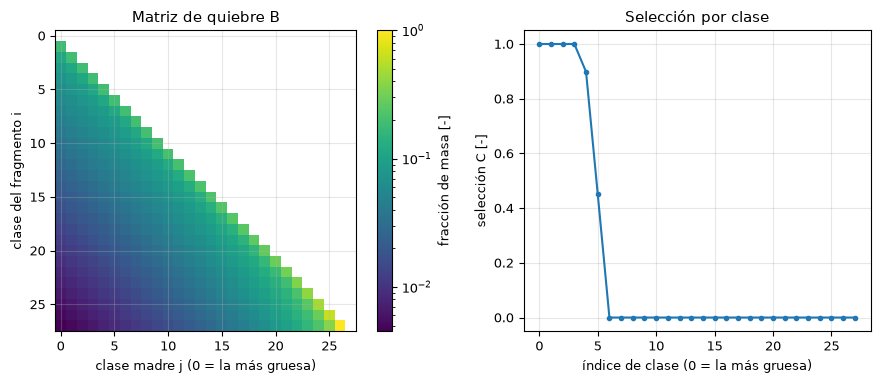

In [4]:
# Muestre B en una escala de color logarítmica y c contra el índice de clase
fig, (left, right) = plt.subplots(1, 2, figsize=(9.2, 3.9), gridspec_kw={"width_ratios": [1.2, 1]})
shown = left.imshow(np.where(B > 0, B, np.nan), norm="log", cmap="viridis")
left.set_xlabel("clase madre j (0 = la más gruesa)")
left.set_ylabel("clase del fragmento i")
left.set_title("Matriz de quiebre B")
fig.colorbar(shown, ax=left, label="fracción de masa [-]")
right.plot(range(K), c, "o-", ms=3)
right.set_xlabel("índice de clase (0 = la más gruesa)")
right.set_ylabel("selección C [-]")
right.set_title("Selección por clase")
fig.tight_layout()
plt.show()

La imagen confirma la estructura que informó la impresión: nada sobre o en la diagonal y un abanico suave bajo ella. El panel derecho muestra que C vale 1 en las primeras cuatro clases, cae a lo largo de dos clases donde el material se separa por azar, y vale 0 de ahí en adelante: solo el material grueso es atrapado, y los finos que ya son menores que K1 salen directamente. La imagen no muestra el balance; el paso siguiente lo escribe.

**Paso 2, el balance de la cámara.** Sea $x$ la masa por clase que llega a la zona de quiebre, contando cada visita. Llega de dos fuentes: la alimentación fresca $f$, y los fragmentos de lo que fue atrapado antes. Una fracción $c_j$ de la clase $j$ es atrapada, y $B$ la reparte, de modo que

$$x = f + B\,C\,x \quad\Longleftrightarrow\quad (I - B C)\,x = f$$

con $C = \mathrm{diag}(c)$. Lo que no es atrapado sale como producto: $p = (I - C)\,x = (I - C)(I - BC)^{-1} f$ (Whiten, 1972; https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf; Napier-Munn et al., 1996). $B C$ es estrictamente triangular inferior, así que $I - BC$ tiene diagonal unitaria y determinante 1: el sistema nunca es singular. La celda arma $M = I - BC$, imprime su diagonal y su indicador de condicionamiento, y resuelve para $x$ con la rutina LU del motor.

In [5]:
# Arme M = I - B C, mire su diagonal y su condicionamiento, y resuelva M x = f con la rutina LU del motor
M = np.eye(K) - B * c[None, :]
x = np.array(solve_lu(M.ravel().tolist(), feed.tolist(), K))
print("diagonal de M, mínimo y máximo:", np.diag(M).min(), np.diag(M).max())
print("indicador de condicionamiento:", round(cond_proxy(M.ravel().tolist(), K), 4))
print("masa que llega a la zona de quiebre, por unidad de alimentación:", x.sum().round(4))
print("eventos de apriete por unidad de alimentación (suma de c x):", (c * x).sum().round(4))

diagonal de M, mínimo y máximo: 1.0 1.0
indicador de condicionamiento: 1.517
masa que llega a la zona de quiebre, por unidad de alimentación: 1.8858
eventos de apriete por unidad de alimentación (suma de c x): 0.8858


La solución tiene una lectura directa. Por cada unidad de alimentación fresca llegan 1,8858 unidades de masa a la zona de quiebre, de modo que cada unidad de alimentación es atrapada, en promedio, 0,8858 veces: la primera visita de una partícula gruesa la quiebra, los fragmentos que siguen sobre el rango de selección vuelven y son atrapados otra vez, y así. La recirculación es la razón de que la abertura cambie el producto más de lo que sugeriría un solo evento de quiebre. El producto sale de $x$.

**Paso 3, el producto y la comprobación.** El producto es la parte de $x$ que no es atrapada, $p = (1 - c) \odot x$, y su total es el total de la alimentación porque la solución conservó la masa. El solucionador propio del motor, `whiten_solve`, hace lo mismo en una llamada. La celda calcula el producto desde $x$, lo compara con el del motor, y declara el cierre de masa con el oráculo, que compara el total del producto con el de la alimentación sin usar el solucionador.

In [6]:
# Producto desde la solución, frente al solucionador propio del motor, y cierre de masa desde el oráculo
product = (1 - c) * x
engine = whiten_solve(c.tolist(), B.ravel().tolist(), feed.tolist(), K)
print("mayor diferencia con el producto del motor:", np.abs(product / product.sum() - np.array(engine.product)).max())
print("cierre de masa, oráculo:", mass_closure(feed.tolist(), product.tolist()), "| motor:", engine.mass_closure)
print("P80", round(size_at_passing(to_psd(edges, product.tolist()), 0.8), 3), "mm | motor", round(result.p80, 3), "mm")

mayor diferencia con el producto del motor: 2.7755575615628914e-17
cierre de masa, oráculo: 0.0 | motor: 3.3306690738754696e-16
P80 27.698 mm | motor 27.698 mm


Las tres vistas de la solución caben en una figura: la alimentación fresca $f$, la masa $x$ que llega a la zona de quiebre, y el producto $p$. La diferencia entre $x$ y $f$ es la masa recirculada, y la diferencia entre $x$ y $p$ es lo que se aprieta.

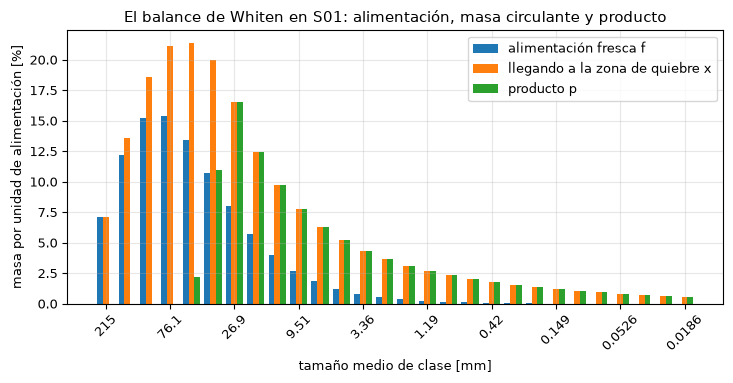

tamaños medios de clase donde x supera a f [mm]: [152.2, 107.6, 76.1, 53.8, 38.1, 26.9, 19.0, 13.5, 9.5, 6.7, 4.8, 3.4, 2.4, 1.7, 1.2, 0.8, 0.6, 0.4, 0.3, 0.2, 0.1, 0.1, 0.1, 0.1, 0.0, 0.0, 0.0]
clases donde el producto es cero: 4


In [7]:
# Gráfico de barras de la alimentación, la masa que llega a la zona de quiebre y el producto, por clase
position = np.arange(K)
series = ((-0.27, feed, "alimentación fresca f"), (0, x, "llegando a la zona de quiebre x"),
          (0.27, product, "producto p"))
fig, ax = plt.subplots()
for shift, values, label in series:
    ax.bar(position + shift, values * 100, 0.27, label=label)
ax.set_xticks(position[::3], [f"{m:.3g}" for m in mids[::3]], rotation=45)
ax.set_xlabel("tamaño medio de clase [mm]")
ax.set_ylabel("masa por unidad de alimentación [%]")
ax.set_title("El balance de Whiten en S01: alimentación, masa circulante y producto")
ax.legend()
fig.tight_layout()
plt.show()
recirculated = [round(m, 1) for m, a, b in zip(mids, x, feed) if a > b + 1e-9]
print("tamaños medios de clase donde x supera a f [mm]:", recirculated)
print("clases donde el producto es cero:", int((product == 0).sum()))

En la clase más gruesa las barras de $x$ y de $f$ coinciden, porque ningún fragmento puede volver sobre el tamaño máximo de la alimentación; en cada clase bajo ella $x$ supera a $f$ en los fragmentos recirculados, como muestra la lista impresa de clases. El producto $p$ es cero en las cuatro clases que siempre son atrapadas y lleva toda su masa bajo ellas. La figura no dice cómo depende el producto de la abertura, porque está dibujada con una; el paso siguiente la mueve.

**Paso 4, recirculación frente a la abertura.** La celda repite la construcción para aberturas de lado cerrado de 40 a 160 por ciento de la de S01, pidiendo a `assemble_chamber` la clasificación de cada abertura (la matriz de quiebre no depende de la abertura y sigue siendo la misma $B$), resuelve cada sistema con la misma rutina LU y registra los eventos de apriete por unidad de alimentación y el P80 del producto. Una abertura más cerrada selecciona partículas más pequeñas, de modo que más fragmentos califican para un segundo apriete.

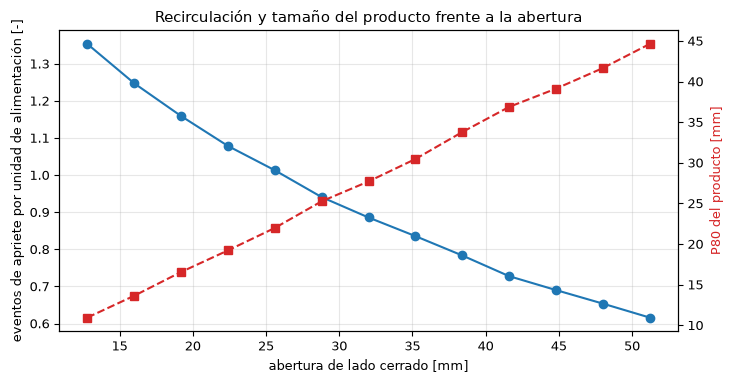

eventos de apriete con la abertura más cerrada y la más ancha: 1.353 0.616
P80 con la abertura más cerrada y la más ancha [mm]: 10.95 44.62


In [8]:
# Repita la solución para un rango de aberturas de lado cerrado: eventos de apriete por unidad de alimentación y P80
settings = op.css_mm * np.linspace(0.4, 1.6, 13)
nips, p80s = [], []
for css in settings:
    cc, _ = assemble_chamber(replace(op, css_mm=float(css)))
    xx = np.array(solve_lu((np.eye(K) - B * cc[None, :]).ravel().tolist(), feed.tolist(), K))
    nips.append((cc * xx).sum())
    p80s.append(size_at_passing(to_psd(edges, ((1 - cc) * xx).tolist()), 0.8))
fig, ax = plt.subplots()
ax.plot(settings, nips, "o-")
ax.set_xlabel("abertura de lado cerrado [mm]")
ax.set_ylabel("eventos de apriete por unidad de alimentación [-]")
twin = ax.twinx()
twin.plot(settings, p80s, "s--", color="tab:red")
twin.set_ylabel("P80 del producto [mm]", color="tab:red")
twin.grid(False)
ax.set_title("Recirculación y tamaño del producto frente a la abertura")
fig.tight_layout()
plt.show()
print("eventos de apriete con la abertura más cerrada y la más ancha:", round(nips[0], 3), round(nips[-1], 3))
print("P80 con la abertura más cerrada y la más ancha [mm]:", round(p80s[0], 2), round(p80s[-1], 2))

Cerrar la abertura de 160 a 40 por ciento de la de S01 sube los eventos de apriete de 0,62 a 1,35 por unidad de alimentación y baja el P80 de 44,62 mm a 10,95 mm, un factor de cuatro, de modo que un chancador cerrado hace su trabajo en varias visitas y no en una. Este es el mecanismo detrás de los compromisos de capacidad y potencia del tema 04: más apriete por tonelada es más energía por tonelada. La curva es suave, sin cambio de régimen dentro del rango: el modelo no predice el atoramiento, lo marca aparte con la lógica de regímenes del motor.

**Paso 5, hasta dónde se puede llevar el balance.** La diagonal unitaria de $I - BC$ dice que el sistema se puede resolver con cualquier abertura, y el indicador de condicionamiento y el cierre de masa son los números que mostrarían un problema si no fuera así. La celda pide al motor ambos en diez aberturas de 1 mm a 140 mm, la última mayor que el F80 de la alimentación, e imprime el régimen y la validez que el motor asigna.

In [9]:
# Condicionamiento, cierre de masa y régimen del motor en diez aberturas, de muy cerrada a más ancha que F80
wide_range = [evaluate(replace(op, css_mm=float(css))) for css in (1, 2, 4, 8, 16, 32, 64, 100, 126, 140)]
for r in wide_range:
    print(f"CSS {r.op.css_mm:5.0f} mm  cond {r.cond_estimate:.3f}  cierre {r.mass_closure:.1e}",
          f" P80 {r.p80:7.2f} mm  {r.regime:12s} válido={r.valid}")
worst_closure = max(r.mass_closure for r in wide_range)
worst_cond = max(r.cond_estimate for r in wide_range)
print("mayor cierre:", f"{worst_closure:.1e}", "| mayor indicador de condicionamiento:", round(worst_cond, 3))
tightest = wide_range[0]
print("advertencias con la abertura más cerrada, CSS 1 mm:", tightest.flags, "| válido:", tightest.valid)

CSS     1 mm  cond 1.831  cierre 5.6e-16  P80    1.83 mm  choke        válido=True
CSS     2 mm  cond 1.807  cierre 5.6e-16  P80    2.53 mm  choke        válido=True
CSS     4 mm  cond 1.763  cierre 7.8e-16  P80    3.99 mm  choke        válido=True
CSS     8 mm  cond 1.700  cierre 5.6e-16  P80    7.04 mm  choke        válido=True
CSS    16 mm  cond 1.621  cierre 5.6e-16  P80   13.63 mm  choke        válido=True
CSS    32 mm  cond 1.517  cierre 3.3e-16  P80   27.70 mm  choke        válido=True
CSS    64 mm  cond 1.378  cierre 3.3e-16  P80   55.41 mm  choke        válido=True
CSS   100 mm  cond 1.274  cierre 2.2e-16  P80   81.41 mm  choke        válido=True
CSS   126 mm  cond 1.208  cierre 3.3e-16  P80   98.13 mm  choke        válido=True
CSS   140 mm  cond 1.164  cierre 5.6e-16  P80  103.45 mm  pass-through válido=False
mayor cierre: 7.8e-16 | mayor indicador de condicionamiento: 1.831
advertencias con la abertura más cerrada, CSS 1 mm: ('css_below_vendor_minimum', 'reduction_ratio_abov

El indicador de condicionamiento se mantiene entre 1,16 y 1,83 y el cierre bajo 1e-15 con cada abertura, cerrada o ancha, de modo que la numérica nunca se rompe: una mala respuesta del motor nunca es una solución fallida. Lo que cambia en 140 mm es la física, no el álgebra: la abertura excede el F80 (126 mm), el motor asigna el régimen de paso directo y marca el punto inválido, porque un chancador ajustado más ancho que su alimentación no la quiebra. El balance aún entregaría un número, y la marca de validez es lo que evita que se lea como una predicción.

El extremo cerrado no es una salvaguarda de ese tipo, y el motor ahora lo dice. La primera fila de la salida es una abertura de lado cerrado de 1 mm en un cono secundario alimentado con F80 126 mm, todavía válida y en régimen de cámara llena (choke), y la última línea de la salida imprime las advertencias que levanta: `css_below_vendor_minimum` (1 mm está bajo la abertura mínima de 16 mm del Metso HP500 con revestimientos estándar) y `reduction_ratio_above_typical` (la razón de reducción supera con holgura el 3 a 5 de una cámara estándar). Una advertencia nunca vuelve inválido el punto, porque el fabricante considera blanda la abertura mínima, así que la marca sigue en True. Quien lea la fila no debe tomarla como predicción: el motor le dice que la abertura está bajo lo que la máquina admite, y el número es una extrapolación del modelo, no un resultado del balance.

## Resultados

**Respuesta:** con la abertura de S01 una unidad de alimentación fresca envía 1,8858 unidades de masa a la zona de quiebre, de modo que pasa por el apriete 0,8858 veces en promedio, y el balance entrega un producto con P80 = 27,698 mm, igual al del motor, con una diferencia con el producto del motor de 2,8e-17 y un cierre de masa de 0,0 según el oráculo (3,3e-16 según el motor). Cerrar la abertura a 40 por ciento de la de S01 sube los eventos de apriete a 1,353 y baja el P80 a 10,95 mm, frente a 0,616 y 44,62 mm con 160 por ciento. La marca de validez señala el extremo ancho (CSS 140 mm, paso directo) pero no el cerrado: CSS 1 mm se informa como válido.

La figura de estructura muestra la matriz estrictamente triangular inferior y la selección en dos paneles; el gráfico de barras muestra las tres masas; la última figura la recirculación frente a la abertura. Un validador concluiría que el balance de Whiten se resuelve exactamente, pues el oráculo independiente cierra la masa a precisión de máquina y la solución paso a paso coincide con el solucionador del motor a 1e-16, y que la respuesta del modelo a la abertura pasa por la recirculación. Lo que estas comprobaciones no muestran es que B y C del modelo sean correctas para una planta dada: son las formas publicadas con las constantes del motor, y los muestreos reales del tema 05 son donde se encuentran con una medición.

## Resumen

El modelo del chancador es un sistema lineal: $(I - BC)\,x = f$, resuelto exactamente y sin formar nunca una inversa, y leído luego como producto y como recirculación. La solución dice cuántas veces pasa el material por el apriete, que es la palanca que mueve la abertura. La solución paso a paso coincide con el solucionador propio del pipeline; el notebook que sigue muestrea las mismas B y C con la regla de reemplazo de partículas que usan los modelos de elementos discretos de chancadores, y muestra que el balance es la esperanza de esa regla.

## Referencias

- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193